In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,classification_report

In [2]:
df = pd.read_csv(r"D:\Sasi\GUVI HCL AI-ML\EV_Charging Project\data\cleaned\FEChargingRecords.csv")

if 'Duration' in df.columns:
  df = df[df['Duration'] > 0].copy()

In [3]:
median_demand = df['Demand'].median()
print(f"Median Demand Threshold: {median_demand:.2f}")

df['Demand_Class'] = (df['Demand'] >= median_demand).astype(int)
df.head()

Median Demand Threshold: 14.25


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDatetime,EndDatetime,Duration,Demand,Start_Hour,Start_DayOfWeek,Start_Month,Is_Weekend,TimeOfDay,Is_Peak_Hour,Demand_Class
0,0,1,1,hotel,0,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,3,9,0,Evening,1,1
1,0,1,1,hotel,0,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,2,9,0,Evening,1,0
2,0,1,1,hotel,0,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,2,9,0,Evening,1,0
3,0,1,1,hotel,0,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,3,9,0,Evening,1,1
4,0,1,1,hotel,0,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,6,9,1,Evening,1,1


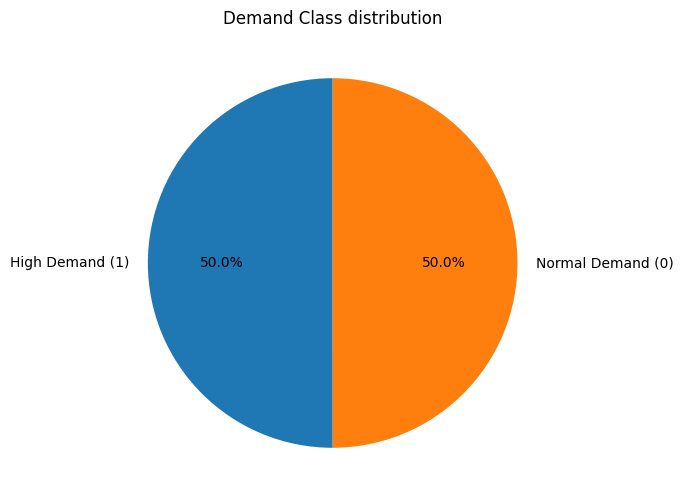

Class Imbalance Check:
Demand_Class
1    36150
0    36146
Name: count, dtype: int64


In [4]:
demand_class = df['Demand_Class'].value_counts()
demand_class.index = demand_class.index.map({0:'Normal Demand (0)',1:'High Demand (1)'})
plt.figure(figsize=(6,6))
plt.pie(demand_class,labels=demand_class.index,autopct='%1.1f%%',startangle=90)
plt.title('Demand Class distribution')
plt.show()
print("Class Imbalance Check:")
print(df['Demand_Class'].value_counts())

In [5]:
base_features = [
    'ChargerID',
    'ChargerCompany',
    'Location',
    'ChargerType',
    'Duration',
    'Start_Hour',
    'Start_DayOfWeek',
    'Start_Month',
    'Is_Weekend',
]
if 'Is_Peak_Hour' in df.columns:
  base_features.append('Is_Peak_Hour')

X = df[base_features]
y = df['Demand_Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

location_means = y_train.groupby(X_train['Location']).mean().to_dict()
global_mean = y_train.mean()

X_train['Location_TargetEncoded'] = (X_train['Location'].map(location_means).fillna(global_mean))
X_test['Location_TargetEncoded'] = (X_test['Location'].map(location_means).fillna(global_mean))

final_features = [
    'ChargerID',
    'ChargerCompany',
    'Location_TargetEncoded',
    'ChargerType',
    'Duration',
    'Start_Hour',
    'Start_DayOfWeek',
    'Start_Month',
    'Is_Weekend',
]
if 'Is_Peak_Hour' in X_train.columns and 'Is_Peak_Hour' not in final_features:
  final_features.append('Is_Peak_Hour')

X_train = X_train[final_features]
X_test = X_test[final_features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": (LogisticRegression(random_state=42), X_train_scaled, X_test_scaled),
    "KNN": (KNeighborsClassifier(n_jobs=-1), X_train_scaled, X_test_scaled),
    "Random Forest": (RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1), X_train, X_test),
    "SVM": (SVC(probability=True, random_state=42), X_train_scaled, X_test_scaled),
    "XGBoost": (xgb.XGBClassifier(random_state=42, n_jobs=-1), X_train, X_test),
    "CatBoost": (CatBoostClassifier(random_state=42, verbose=0), X_train, X_test)
}

results = []

In [6]:
for name, (model, X_tr, X_te) in models.items():
    model.fit(X_tr, y_train)
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_te)

    print(f'=== Classification report for {name} ===')
    print(classification_report(y_test, preds, target_names=['Normal Demand','High Demand']))
    print('\n'+'='*50+'\n')
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision": round(precision_score(y_test, preds), 4),
        "Recall": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })

res_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\nClassification Model Comparison:")
res_df

=== Classification report for Logistic Regression ===
               precision    recall  f1-score   support

Normal Demand       0.85      0.80      0.82      7230
  High Demand       0.81      0.86      0.84      7230

     accuracy                           0.83     14460
    macro avg       0.83      0.83      0.83     14460
 weighted avg       0.83      0.83      0.83     14460



=== Classification report for KNN ===
               precision    recall  f1-score   support

Normal Demand       0.86      0.81      0.83      7230
  High Demand       0.82      0.86      0.84      7230

     accuracy                           0.84     14460
    macro avg       0.84      0.84      0.84     14460
 weighted avg       0.84      0.84      0.84     14460



=== Classification report for Random Forest ===
               precision    recall  f1-score   support

Normal Demand       0.94      0.89      0.92      7230
  High Demand       0.90      0.94      0.92      7230

     accuracy          

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
4,XGBoost,0.9205,0.9002,0.9458,0.9224,0.9726
5,CatBoost,0.9187,0.8957,0.9477,0.9210,0.9720
2,Random Forest,0.9178,0.8975,0.9434,0.9199,0.9702
3,SVM,0.8890,0.8638,0.9237,0.8927,0.9429
1,KNN,0.8382,0.8220,0.8635,0.8422,0.9112
0,Logistic Regression,0.8306,0.8103,0.8632,0.8359,0.9041


In [7]:
import pickle
xgb_class_model = models['XGBoost'][0]
model_filename = 'classifier_ev_demand_model.pkl'

# Save the trained model to disk
with open(model_filename, 'wb') as file:
  pickle.dump(xgb_class_model, file)

print(f'Model successfully saved as {model_filename}')

Model successfully saved as classifier_ev_demand_model.pkl


In [14]:
importances = xgb_class_model.feature_importances_
sorted_features = sorted(zip(X_train.columns, importances),key=lambda x:x[1],reverse=True)
for feature, importance in sorted_features:
    print(f'{feature}:{importance:.4f}')

ChargerType:0.7830
Duration:0.0901
ChargerCompany:0.0744
ChargerID:0.0165
Location_TargetEncoded:0.0118
Start_Hour:0.0076
Is_Peak_Hour:0.0068
Start_Month:0.0060
Start_DayOfWeek:0.0037
Is_Weekend:0.0000


In [15]:
with open(model_filename, 'rb') as file:
  loaded_classifier = pickle.load(file)

score = loaded_classifier.score(X_test, y_test)
print(f'Loaded model test accuracy: {score:.4f}')

Loaded model test accuracy: 0.9205


100%|██████████| 20/20 [00:00<00:00, 36.81it/s]


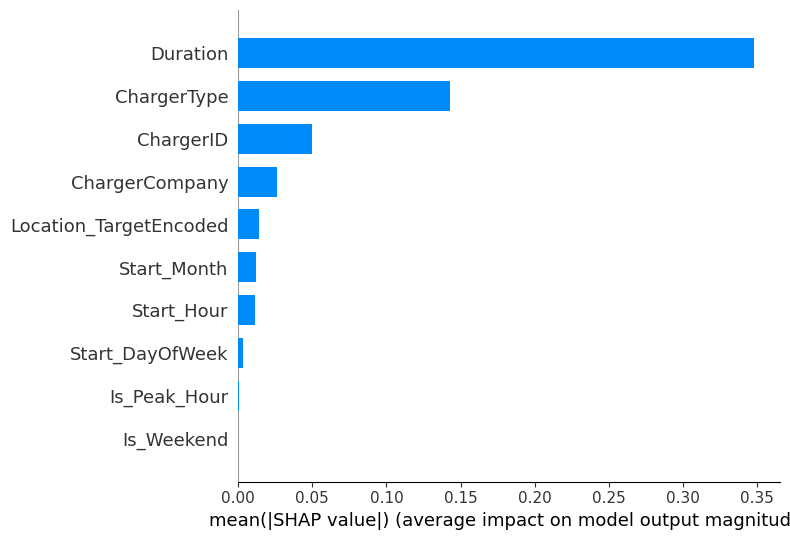

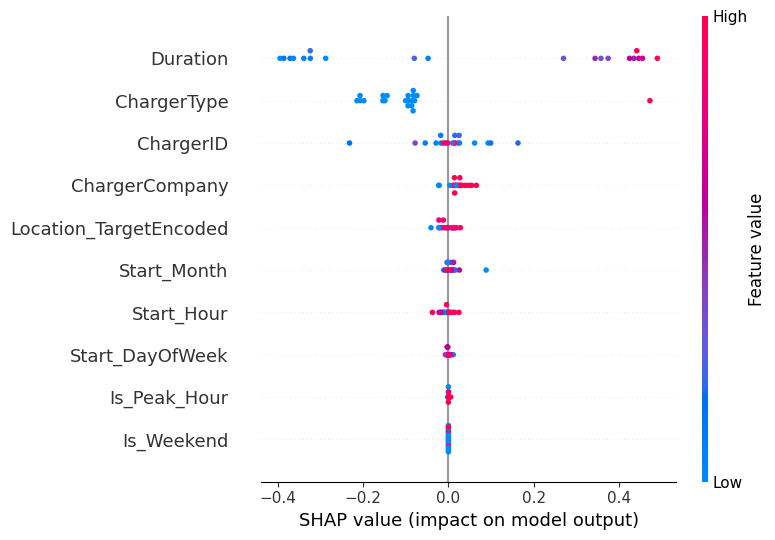

In [16]:
import shap

# 1. Create a background dataset using a small subset or k-means summary
background = X_train.iloc[:50] 

# 2. Wrap the prediction function in a lambda to prevent attribute injection
predict_fn = lambda x: xgb_class_model.predict_proba(x)

# 3. Initialize KernelExplainer using the wrapper function
explainer = shap.KernelExplainer(predict_fn, background)

# 4. Calculate SHAP values on a subset of test data (KernelExplainer is computationally intensive)
shap_values = explainer.shap_values(X_test.iloc[:20])

# 5. Generate summary plot

# Summary plot (Global feature importance and impact direction)
shap.summary_plot(shap_values[:,:,1], X_test.iloc[:20], plot_type='bar')

# Detailed beeswarm plot showing positive/negative feature impacts
shap.summary_plot(shap_values[:,:,1], X_test.iloc[:20])

In [17]:
from lime import lime_tabular
import numpy as np
import pandas as pd

# 1. Initialize LIME Tabular Explainer in classification mode
explainer_lime = lime_tabular.LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=final_features,
    class_names=[
        'Normal Demand',
        'High Demand',
    ],  # Binary classes: 0 = Normal, 1 = High
    mode='classification',
    random_state=42,
)

# 2. Explain a specific test sample prediction (e.g., test instance index 0)
exp = explainer_lime.explain_instance(
    data_row=X_test.iloc[0],
    predict_fn=xgb_class_model.predict_proba,  # XGBoost probability prediction function
    num_features=5,  # Display top 5 influential features for this instance
)

# 3. Display the local explanation inside a Jupyter Notebook
exp.show_in_notebook()

c:\miniconda_envs\ev_env\lib\site-packages\lime\discretize.py:110: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
c:\miniconda_envs\ev_env\lib\site-packages\lime\discretize.py:110: FutureWarning: Series.__setitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To set a value by position, use `ser.iloc[pos] = value`
  ret[feature] = int(self.lambdas[feature](ret[feature]))
c:\miniconda_envs\ev_env\lib\site-packages\lime\lime_tabular.py:544: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, 